# 04 - Evaluate on my own webcam

**Goal:** the real test. Validation in notebook 03 came from the same signer, camera and room as training (~95%). Here the model sees **my hand, my camera, my room**, which it has never seen.

**Collect first:** `python app/collect_webcam.py --session s1` (right hand, palm toward camera, like the dataset; hold each sign still and move it slightly during the burst). Do about 15 frames for each of A-Z, `1` = space, `2` = del, `0` = nothing (empty scene). Do a **second session** (`--session s2`) with a different distance, lighting or place, ideally another day.

**Questions this notebook answers**
1. Should live frames be flipped before detection? (decided by data, not guessing)
2. How much accuracy is lost on my own hand, and where?
3. What probability threshold should the game use?

Caveat: the 15 frames in a burst are near-twins, so each burst is closer to *one* test sample than fifteen.

In [5]:
import time
from pathlib import Path

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

MODEL_PATH = "../models/mediapipe/hand_landmarker.task"
CKPT_PATH = "../models/mlp_v1.pt"
OWN_DIR = Path("../data/own_webcam")
CONF = 0.3          # MUST match the extraction in notebook 02

# the checkpoint holds numpy arrays, so weights_only=False (it is my own file)
ckpt = torch.load(CKPT_PATH, weights_only=False)
CLASSES, MEAN, STD = ckpt["classes"], ckpt["mean"], ckpt["std"]
print("model trained on:", ckpt["csv_used"], "| hidden:", ckpt["hidden"], "|", len(CLASSES), "classes")

def build(hidden, dropout):
    layers, d = [], 63
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
        d = h
    layers.append(nn.Linear(d, len(CLASSES)))
    return nn.Sequential(*layers)

model = build(ckpt["hidden"], ckpt["dropout"])
model.load_state_dict(ckpt["state_dict"]); model.eval()

model trained on: ../data/processed/keypoints_conf03_stride1.csv | hidden: (128, 64) | 28 classes


Sequential(
  (0): Linear(in_features=63, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=64, out_features=28, bias=True)
)

### The exact same pipeline as training
These three functions are copies of notebook 02 (options, `detect`, `normalize`). Any difference between training and live preprocessing silently ruins accuracy, so these will move into `src/asl_letters/keypoints.py` and be imported from there, never copied again.

In [6]:
def make_options(conf=CONF):
    return vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MODEL_PATH),
        running_mode=vision.RunningMode.IMAGE, num_hands=1,
        min_hand_detection_confidence=conf, min_hand_presence_confidence=conf)

def detect(landmarker, rgb):
    return landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))

def normalize(hand, W, H):
    pts = np.array([[p.x * W, p.y * H, p.z * W] for p in hand], dtype=np.float32)
    pts -= pts[0]
    scale = np.linalg.norm(pts[9, :2])
    if scale < 1e-6:
        return None
    return (pts / scale).reshape(-1)

def predict_rgb(landmarker, rgb, flip=False):
    if flip:
        rgb = cv2.flip(rgb, 1)
    res = detect(landmarker, rgb)
    feats = None
    if res.hand_landmarks:
        H, W = rgb.shape[:2]
        feats = normalize(res.hand_landmarks[0], W, H)
    if feats is None:                                   # no hand -> NOTHING
        return dict(pred="nothing", prob=1.0, found=False, hand=None, lms=None)
    x = torch.tensor(((feats - MEAN) / STD)[None], dtype=torch.float32)
    with torch.no_grad():
        p = torch.softmax(model(x), 1)[0]
    k = int(p.argmax())
    return dict(pred=CLASSES[k], prob=float(p[k]), found=True,
                hand=res.handedness[0][0].category_name, lms=res.hand_landmarks[0])

In [7]:
files = sorted(OWN_DIR.glob("*/*.jpg"))
meta = pd.DataFrame({"path": files,
                     "true": [p.parent.name for p in files],
                     "session": [p.stem.split("_")[1] for p in files]})
print(len(meta), "images")
print(meta.groupby(["true", "session"]).size().unstack(fill_value=0).to_string())

45 images
session  s1
true       
del      15
nothing  15
space    15


## 1. Flip or not? Let the data decide
Run every image **raw** and **flipped**. The dataset is ~Right-handed in MediaPipe's eyes, so the right setup should show a high share of "Right" and higher accuracy.

In [8]:
def run_all(flip):
    rows = []
    with vision.HandLandmarker.create_from_options(make_options()) as lm:
        for p, true, sess in zip(meta.path, meta.true, meta.session):
            rgb = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
            rows.append(dict(path=p, true=true, session=sess, flip=flip, **predict_rgb(lm, rgb, flip)))
    return pd.DataFrame(rows)

t0 = time.perf_counter()
allres = pd.concat([run_all(False), run_all(True)], ignore_index=True)
print(f"{time.perf_counter() - t0:.0f}s")

lett = allres[allres.true != "nothing"]
summary = {}
for flip, d in lett.groupby("flip"):
    f = d[d.found]
    summary["flipped" if flip else "raw"] = {
        "hand_found": d.found.mean(),
        "share_Right": (f.hand == "Right").mean(),
        "acc_when_found": (f.pred == f.true).mean(),
        "system_acc": (d.pred == d.true).mean()}
summary = pd.DataFrame(summary).T
print(summary.round(3).to_string())
FLIP = bool(summary.loc["flipped", "system_acc"] > summary.loc["raw", "system_acc"])
print("chosen FLIP =", FLIP)

2s
         hand_found  share_Right  acc_when_found  system_acc
raw             1.0          1.0             0.5         0.5
flipped         1.0          0.0             0.5         0.5
chosen FLIP = False


**Finding (fill in):** which setup wins, by how much, and does its "Right" share match the dataset? `system_acc` counts a missed hand as a wrong answer, which is what a player experiences; `acc_when_found` shows the classifier alone.

## 2. Accuracy on my own hand

In [9]:
df = allres[allres.flip == FLIP].copy()
L = df[df.true != "nothing"].copy()
L["correct"] = L.pred == L.true

print(f"overall system accuracy: {L.correct.mean():.3f} | hand found: {L.found.mean():.3f} | accuracy when found: {L[L.found].correct.mean():.3f}")
print("\nper session:")
print(L.groupby("session").agg(n=("correct", "size"), found=("found", "mean"), system_acc=("correct", "mean")).round(3).to_string())

pc = L.groupby("true").agg(n=("correct", "size"), found=("found", "mean"), system_acc=("correct", "mean"))
pc["acc_when_found"] = L[L.found].groupby("true").correct.mean()
print("\nper class (worst first):")
print(pc.sort_values("system_acc").round(2).to_string())

N0 = df[df.true == "nothing"]
if len(N0):
    print(f"\n'nothing' frames: false hand rate {N0.found.mean():.3f} | predicted NOTHING {(N0.pred == 'nothing').mean():.3f}")

print("\ntop errors (true -> predicted; 'nothing' = missed hand):")
print(L[~L.correct].groupby(["true", "pred"]).size().sort_values(ascending=False).head(12).to_string())

overall system accuracy: 0.500 | hand found: 1.000 | accuracy when found: 0.500

per session:
          n  found  system_acc
session                       
s1       30    1.0         0.5

per class (worst first):
        n  found  system_acc  acc_when_found
true                                        
del    15    1.0         0.0             0.0
space  15    1.0         1.0             1.0

'nothing' frames: false hand rate 0.000 | predicted NOTHING 1.000

top errors (true -> predicted; 'nothing' = missed hand):
true  pred
del   C       15


**Finding (fill in):** how far is system accuracy below the ~95% validation number? Is the loss from **missed hands** (found rate) or from **wrong letters** (acc when found)? Does session s2 score lower than s1? Which letters fail, and are they the same M/N/A ones as in validation?

## 3. Choosing a confidence threshold for the game
Showing a letter only when the model is confident trades **coverage** (how often the game reacts) against **accuracy** of what it shows. The game will also require N consecutive agreeing frames, which filters out most flicker.

In [10]:
rows = []
for t in [0.0, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99]:
    shown = L.found & (L.prob >= t)
    rows.append(dict(threshold=t, coverage=shown.mean(), accuracy_of_shown=L[shown].correct.mean()))
print(pd.DataFrame(rows).round(3).to_string(index=False))

 threshold  coverage  accuracy_of_shown
      0.00       1.0              0.500
      0.50       0.8              0.625
      0.70       0.6              0.833
      0.80       0.5              1.000
      0.90       0.5              1.000
      0.95       0.5              1.000
      0.99       0.3              1.000


## 4. Look at the failures

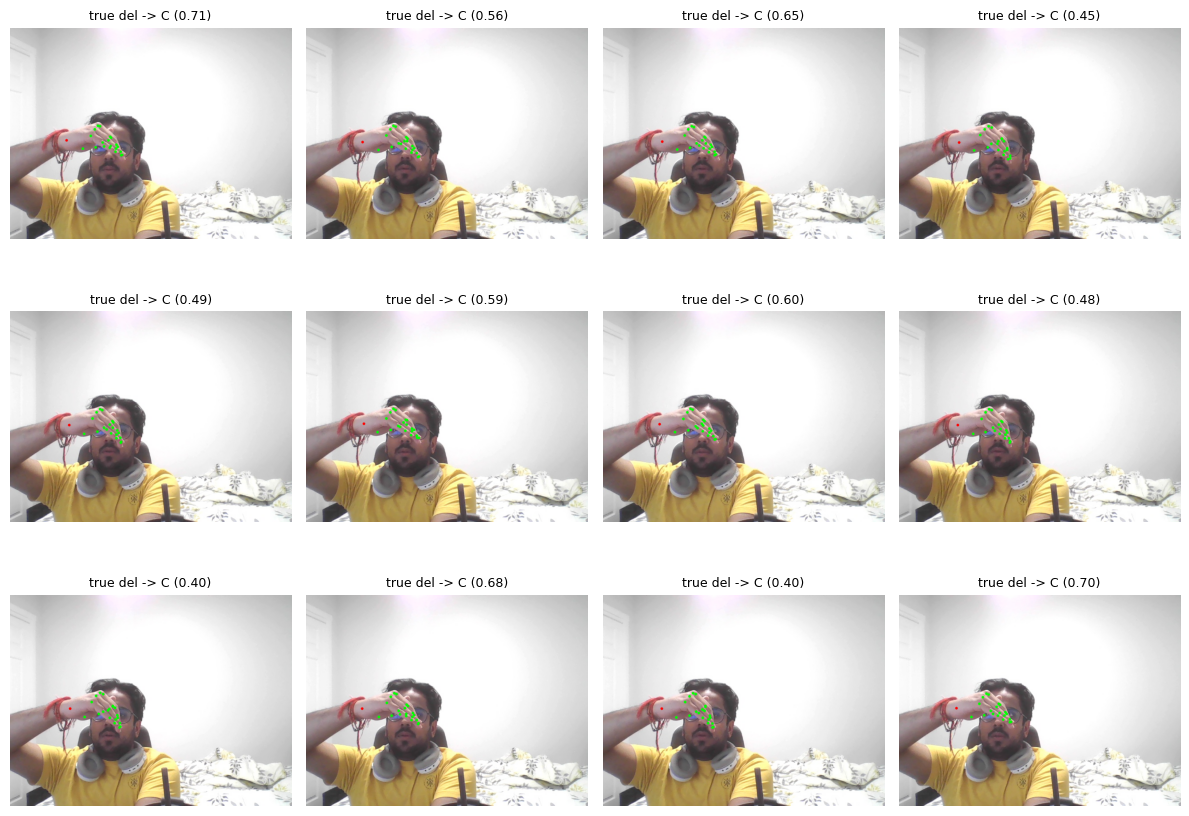

In [11]:
def draw_landmarks(rgb, hand):
    out = rgb.copy()
    H, W = out.shape[:2]
    for i, p in enumerate(hand):
        cv2.circle(out, (int(p.x * W), int(p.y * H)), 3, (255, 0, 0) if i == 0 else (0, 255, 0), -1)
    return out

bad = L[~L.correct].sample(min(12, int((~L.correct).sum())), random_state=0) if (~L.correct).any() else L.iloc[:0]
if len(bad):
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), bad.iterrows()):
        rgb = cv2.cvtColor(cv2.imread(str(r.path)), cv2.COLOR_BGR2RGB)
        if FLIP:
            rgb = cv2.flip(rgb, 1)
        ax.imshow(draw_landmarks(rgb, r.lms) if r.found else rgb)
        ax.set_title(f"true {r.true} -> {r.pred} ({r.prob:.2f})", fontsize=9)
    plt.tight_layout(); plt.show()

**Finding (fill in):** do the failed frames show misplaced landmarks (detector problem), a hand pose that differs from the dataset (data problem), or a genuinely ambiguous shape (M/N/A)?

## What to do with the result
- **System accuracy near validation (>~90%):** the model transfers. Move on to the webcam app and game.
- **Big drop, mostly missed hands:** a detector problem. Check lighting, distance and background; the live app can show "move your hand into view" guidance.
- **Big drop, wrong letters when found:** a domain gap. Fix by **adding my own frames to training** (s1 for training, s2 as the untouched test), possibly with small random rotation/scale noise on the keypoints. That is the V2 plan from the project context.
- **Same few letters fail (M/N/A/T):** consider extra features (e.g. thumb-tip distances to finger bases) or accepting the limitation and telling the player.

## Findings (write after running)
- Flip or not, with the numbers
- System accuracy vs the ~95% validation number, split into missed hands vs wrong letters
- Weakest letters on my own hand
- The chosen probability threshold and why
- What I would try next